In [5]:
# Run this cell only if required
#!pip install numpy matplotlib scikit-learn
#!pip install pandas 

   ---------------------------------------- 0.0/9.8 MB ? eta -:--:--
   --------- ------------------------------ 2.4/9.8 MB 13.7 MB/s eta 0:00:01
   ----------------------- ---------------- 5.8/9.8 MB 15.8 MB/s eta 0:00:01
   ---------------------------------------  9.7/9.8 MB 17.0 MB/s eta 0:00:01
   ---------------------------------------- 9.8/9.8 MB 15.1 MB/s  0:00:00



[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


=== File & Directory Verification ===
Train directory resolved to: train\train
Test directory resolved to:  test\test
train_labels.csv columns:    ['image_id', 'class']
sample_submission.csv columns: ['image_id', 'class']

=== Dataset Summary ===
Total labeled training images in CSV: 63660
Total test images in folder:          29442

=== Number of Images per Class ===
class
CatEye      13884
DogEye      11580
CatNose      6942
CatFace      6942
CatMouth     6942
DogMouth     5790
DogFace      5790
DogNose      5790
Name: count, dtype: int64


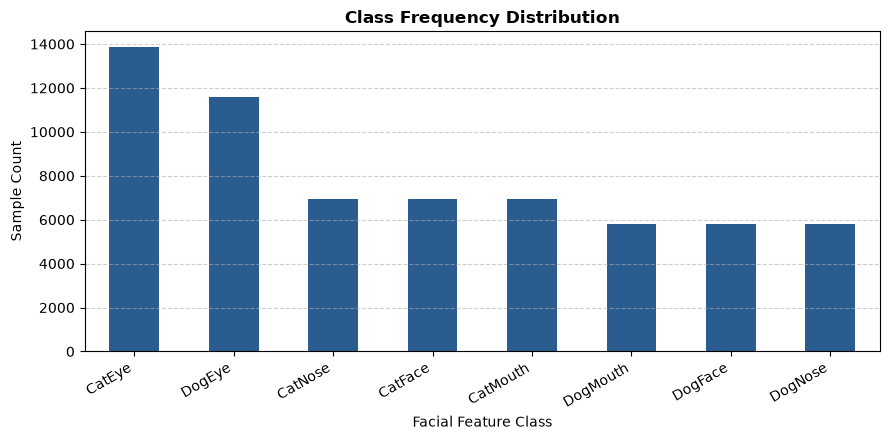

=== Image Quality Audit ===
Corrupted or missing images: 9999
Smallest image resolution : 4 x 4
Largest image resolution  : 2190 x 2070
Average image resolution  : 113 x 109


FileNotFoundError: [Errno 2] No such file or directory: 'train\\train\\15.jpg'

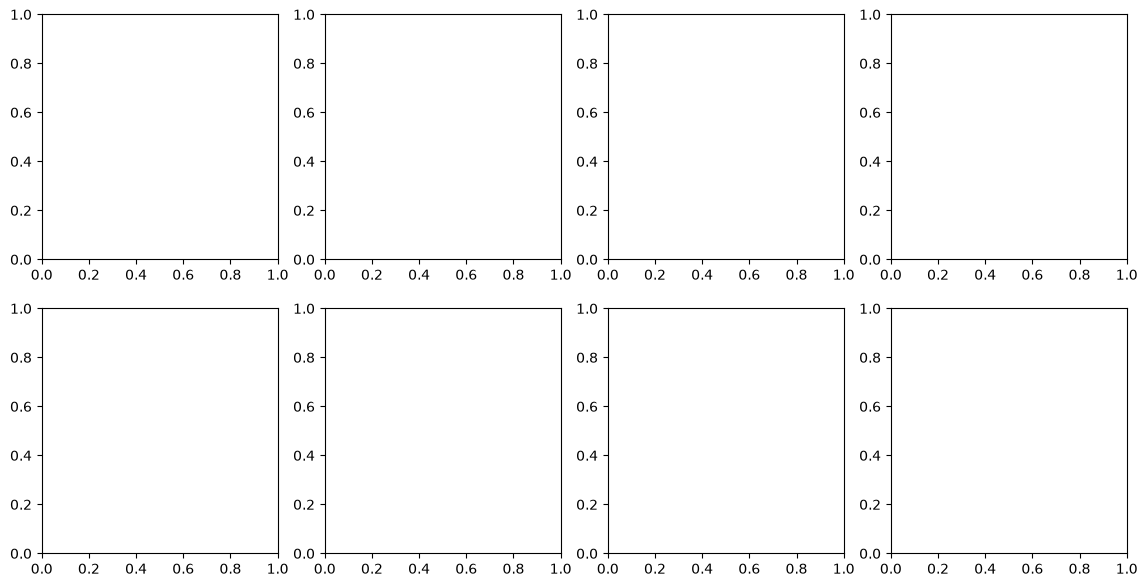

In [12]:
import os
import glob
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

# 1. Paths relative to root folder
TRAIN_LABELS_CSV = "train_labels.csv"
SAMPLE_SUB_CSV = "sample_submission.csv"

# Handle the nested folders created when unzipping
TRAIN_IMG_DIR = os.path.join("train", "train") if os.path.exists(os.path.join("train", "train")) else "train"
TEST_IMG_DIR = os.path.join("test", "test") if os.path.exists(os.path.join("test", "test")) else "test"

# 2. Inspect CSV headers and structure
df = pd.read_csv(TRAIN_LABELS_CSV)
sample_sub = pd.read_csv(SAMPLE_SUB_CSV)

print("=== File & Directory Verification ===")
print(f"Train directory resolved to: {TRAIN_IMG_DIR}")
print(f"Test directory resolved to:  {TEST_IMG_DIR}")
print(f"train_labels.csv columns:    {df.columns.tolist()}")
print(f"sample_submission.csv columns: {sample_sub.columns.tolist()}\n")

# Detect column names automatically
id_col = "image_id" if "image_id" in df.columns else df.columns[0]
target_col = "class" if "class" in df.columns else df.columns[1]

print("=== Dataset Summary ===")
print(f"Total labeled training images in CSV: {len(df)}")
test_files = os.listdir(TEST_IMG_DIR)
print(f"Total test images in folder:          {len(test_files)}\n")

# 3. Class Counts and Distribution
print("=== Number of Images per Class ===")
class_counts = df[target_col].value_counts()
print(class_counts)

# Visualise and save class balance
plt.figure(figsize=(9, 4.5))
class_counts.plot(kind="bar", color="#2b5c8f")
plt.title("Class Frequency Distribution", fontsize=12, fontweight="bold")
plt.xlabel("Facial Feature Class")
plt.ylabel("Sample Count")
plt.xticks(rotation=30, ha="right")
plt.grid(axis="y", linestyle="--", alpha=0.6)
plt.tight_layout()
plt.savefig("class_distribution.png", dpi=300)
plt.show()

# 4. Check for Corruptions, Image Sizes & Extensions
widths, heights = [], []
corrupt_images = []

for raw_id in df[id_col]:
    filename = str(raw_id)
    if not filename.lower().endswith((".jpg", ".png", ".jpeg")):
        filename += ".jpg"
    
    img_path = os.path.join(TRAIN_IMG_DIR, filename)

    try:
        with Image.open(img_path) as img:
            w, h = img.size
            widths.append(w)
            heights.append(h)
    except Exception as e:
        corrupt_images.append((filename, str(e)))

print("=== Image Quality Audit ===")
print(f"Corrupted or missing images: {len(corrupt_images)}")
if widths and heights:
    print(f"Smallest image resolution : {min(widths)} x {min(heights)}")
    print(f"Largest image resolution  : {max(widths)} x {max(heights)}")
    print(f"Average image resolution  : {sum(widths)//len(widths)} x {sum(heights)//len(heights)}")

# 5. Visualise 1 Sample Image per Class
unique_classes = sorted(df[target_col].unique())
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
axes = axes.flatten()

for i, cls_name in enumerate(unique_classes):
    sample_id = df[df[target_col] == cls_name][id_col].iloc[0]
    filename = str(sample_id)
    if not filename.lower().endswith((".jpg", ".png", ".jpeg")):
        filename += ".jpg"
        
    sample_path = os.path.join(TRAIN_IMG_DIR, filename)
    img = Image.open(sample_path)
    
    axes[i].imshow(img)
    axes[i].set_title(f"{cls_name}\n({img.size[0]}x{img.size[1]})", fontsize=10)
    axes[i].axis("off")

plt.suptitle("Representative Samples per Feature Class", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig("sample_classes.png", dpi=300)
plt.show()